#Practical No-05
#Title: Image Generation using Pretrained Stable Diffusion
Name: Nagawade Chirag Somnath

PRN: 202502110009

Subject: Generative AI

# Text-to-Image Generation with a Pretrained Stable Diffusion Model

**Aim:** Use a pretrained Stable Diffusion model through Hugging Face `diffusers` to generate images from text prompts, and analyse how **(1) number of inference steps**, **(2) guidance scale (CFG)** and **(3) the sampling method (scheduler)** affect image quality.


In [1]:
!pip install -q diffusers transformers accelerate safetensors pandas matplotlib

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import (
    DiffusionPipeline,
    PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler,
    UniPCMultistepScheduler,
)
warnings.filterwarnings("ignore")

# ---------------- Configuration ----------------
QUICK_MODE = False          # True -> fewer settings per experiment (fastest)
RESOLUTION = 256            # 256 is fast on CPU; try 384 / 512 for better detail (slower)
SEED       = 42
USE_CLIP   = True           # CLIP score = how well image matches prompt (downloads ~600 MB once)
OUT_DIR    = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

torch.set_num_threads(os.cpu_count())
device = "cpu"
print("Device:", device, "| CPU threads:", torch.get_num_threads(), "| torch", torch.__version__)

Device: cpu | CPU threads: 2 | torch 2.11.0+cu130


## 1. Load the pretrained model

In [3]:
model_id = "segmind/tiny-sd"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float32,   # CPU -> float32
    safety_checker=None,         # faster; avoids false-positive black images
    requires_safety_checker=False,
)
pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)   # keep notebook output clean

BASE_SCHEDULER_CONFIG = pipe.scheduler.config
print("Default scheduler:", pipe.scheduler.__class__.__name__)

model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Default scheduler: DPMSolverMultistepScheduler


## 2. Helper functions

In [4]:
SCHEDULERS = {
    "PNDM":          PNDMScheduler,
    "DDIM":          DDIMScheduler,
    "Euler":         EulerDiscreteScheduler,
    "Euler-Ancestral": EulerAncestralDiscreteScheduler,
    "DPM++ 2M":      DPMSolverMultistepScheduler,
    "UniPC":         UniPCMultistepScheduler,
}

def set_scheduler(name):
    pipe.scheduler = SCHEDULERS[name].from_config(BASE_SCHEDULER_CONFIG)

records = []   # every generated image is logged here for the final summary table

def generate(prompt, steps=20, guidance=7.5, scheduler="DPM++ 2M", seed=SEED, experiment="misc"):
    """Generate one image, time it, log it."""
    set_scheduler(scheduler)
    gen = torch.Generator(device="cpu").manual_seed(seed)
    t0 = time.time()
    img = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance,
               height=RESOLUTION, width=RESOLUTION, generator=gen).images[0]
    dt = time.time() - t0
    records.append(dict(experiment=experiment, prompt=prompt[:40], steps=steps,
                        guidance=guidance, scheduler=scheduler, time_s=round(dt, 2), image=img))
    return img, dt

def show_grid(images, titles, ncols=None, suptitle=None, size=3.2):
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size*ncols, size*nrows + 0.5))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout(); plt.show()

def sharpness(img):
    """Variance of Laplacian on grayscale - higher = more fine detail/edges (not always 'better': noise also raises it)."""
    g = np.asarray(img.convert("L"), dtype=np.float32)
    lap = (-4*g[1:-1,1:-1] + g[:-2,1:-1] + g[2:,1:-1] + g[1:-1,:-2] + g[1:-1,2:])
    return float(lap.var())

def mse(a, b):
    return float(np.mean((np.asarray(a, dtype=np.float32) - np.asarray(b, dtype=np.float32))**2))

### Optional: CLIP score (prompt-image alignment)
CLIP embeds both the text and the image; the cosine similarity (x100) tells how well the picture matches the prompt. Higher = better match. If the download fails, the notebook simply skips this metric.

In [5]:
clip_ok = False
if USE_CLIP:
    try:
        from transformers import CLIPModel, CLIPProcessor
        clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
        clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        clip_ok = True
    except Exception as e:
        print("CLIP not available, skipping CLIP score ->", e)

@torch.no_grad()
def clip_score(img, prompt):
    if not clip_ok: return float("nan")
    inp = clip_proc(text=[prompt], images=img, return_tensors="pt", padding=True, truncation=True)
    out = clip_model(**inp)
    t = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    i = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    return float((t * i).sum() * 100)
print("CLIP enabled:", clip_ok)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP enabled: True


## 3. First image (same idea as the sample notebook, new prompt)
The sample used a smart-farm prompt. Here we use a different prompt - a mountain cabin - which will also be the **base prompt** for the three experiments.

Generated in 79.7s


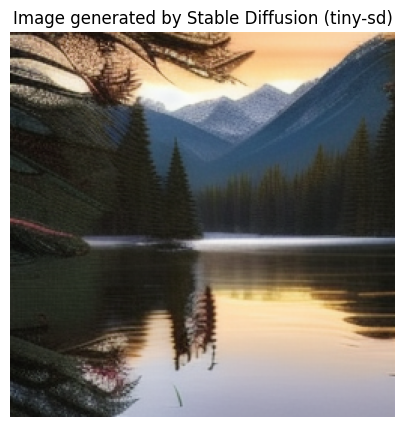

In [6]:
BASE_PROMPT = ("A cozy wooden cabin beside a calm mountain lake at sunrise, "
               "pine trees, soft mist, photorealistic, highly detailed")

img, dt = generate(BASE_PROMPT, steps=20, guidance=7.5, scheduler="DPM++ 2M", experiment="first_image")
print(f"Generated in {dt:.1f}s")
plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
plt.title("Image generated by Stable Diffusion (tiny-sd)"); plt.show()
img.save(f"{OUT_DIR}/first_image.png")

## 4. Experiment 1 - Number of inference steps
Scheduler = DPM++ 2M, guidance = 7.5, same seed. More steps = more denoising iterations = (usually) more detail, but run time grows **linearly**.

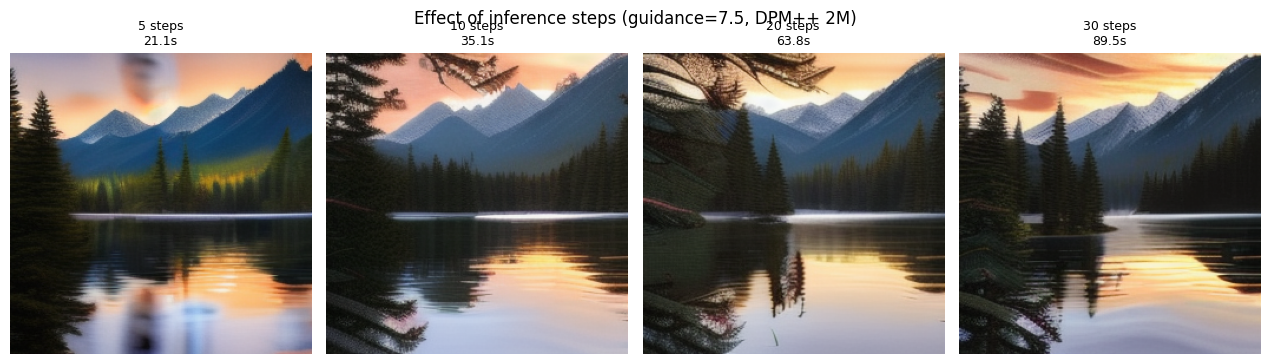

In [7]:
STEP_LIST = [4, 8, 15, 25] if QUICK_MODE else [5, 10, 20, 30]
imgs, titles = [], []
for s in STEP_LIST:
    im, dt = generate(BASE_PROMPT, steps=s, guidance=7.5, scheduler="DPM++ 2M", experiment="steps")
    imgs.append(im); titles.append(f"{s} steps\n{dt:.1f}s")
show_grid(imgs, titles, suptitle="Effect of inference steps (guidance=7.5, DPM++ 2M)")

,steps,time_s,MSE_vs_max_steps,sharpness,CLIP
0,5,21.13,1989.0,535.3,30.34
1,10,35.12,1722.7,842.3,31.92
2,20,63.79,1417.2,959.5,30.99
3,30,89.53,0.0,740.1,31.54


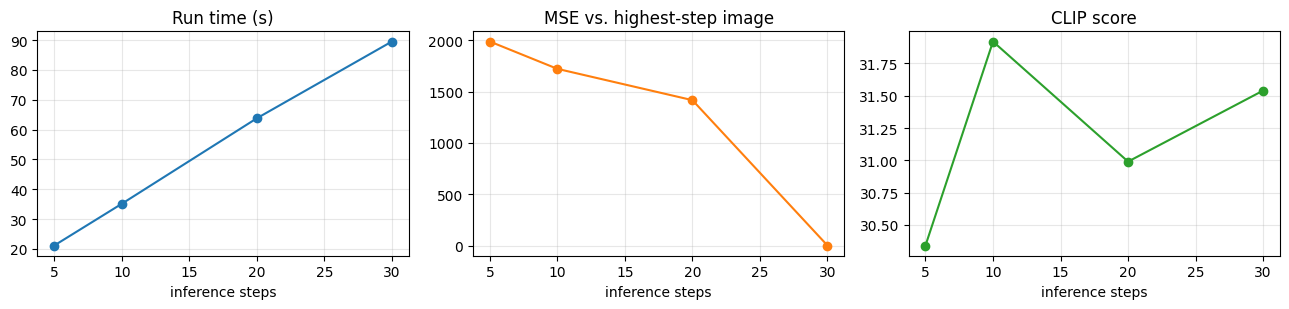

In [8]:
# Quantify: how far is each result from the highest-step image? (convergence) + sharpness + CLIP
ref = imgs[-1]
rows = []
for s, im in zip(STEP_LIST, imgs):
    rows.append(dict(steps=s, time_s=[r["time_s"] for r in records if r["experiment"]=="steps" and r["steps"]==s][0],
                     MSE_vs_max_steps=round(mse(im, ref), 1),
                     sharpness=round(sharpness(im), 1),
                     CLIP=round(clip_score(im, BASE_PROMPT), 2)))
steps_df = pd.DataFrame(rows); display(steps_df)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(steps_df.steps, steps_df.time_s, "o-"); ax[0].set_title("Run time (s)")
ax[1].plot(steps_df.steps, steps_df.MSE_vs_max_steps, "o-", c="C1"); ax[1].set_title("MSE vs. highest-step image")
ax[2].plot(steps_df.steps, steps_df.CLIP, "o-", c="C2"); ax[2].set_title("CLIP score")
for a in ax: a.set_xlabel("inference steps"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**What to look for (typical behaviour - confirm against your own images):**
- Very few steps (4-5) -> blurry, blobby, unfinished images with weak structure.
- Around 15-25 steps -> structure and textures stabilise; the MSE to the highest-step image drops sharply, then flattens (**diminishing returns**).
- Run time grows linearly with steps, so ~20 steps with a good scheduler is the best quality-per-second trade-off on CPU.

## 5. Experiment 2 - Guidance scale (classifier-free guidance)
Steps = 15, scheduler = DPM++ 2M, same seed. The guidance scale controls how strongly the image is pushed towards the prompt versus the model's own "free" imagination.

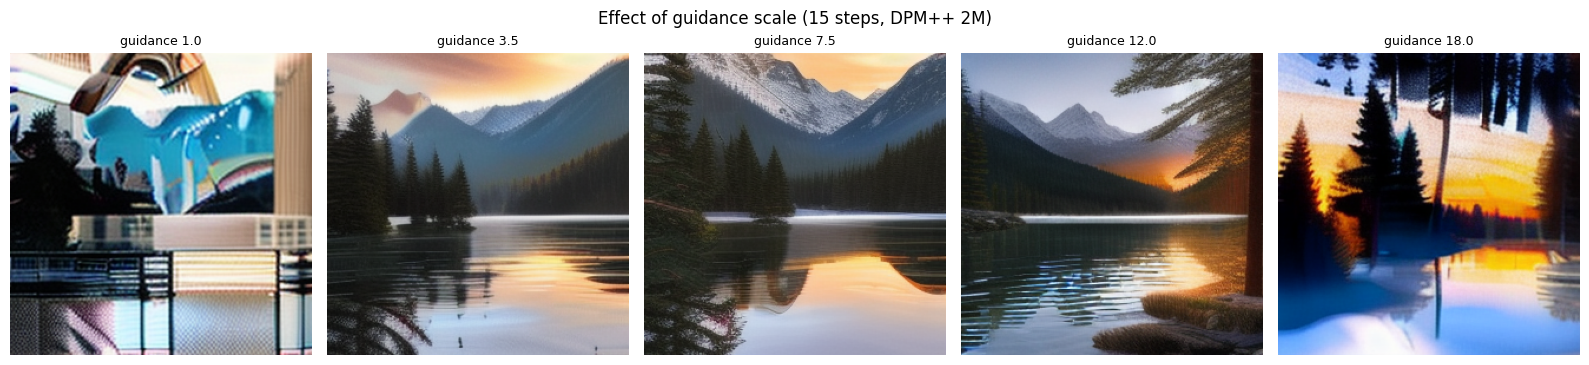

,guidance,time_s,sharpness,CLIP
0,1.0,34.0,875.0,14.41
1,3.5,47.9,583.4,31.16
2,7.5,47.8,986.3,29.75
3,12.0,47.8,1516.9,35.66
4,18.0,48.0,550.4,31.98


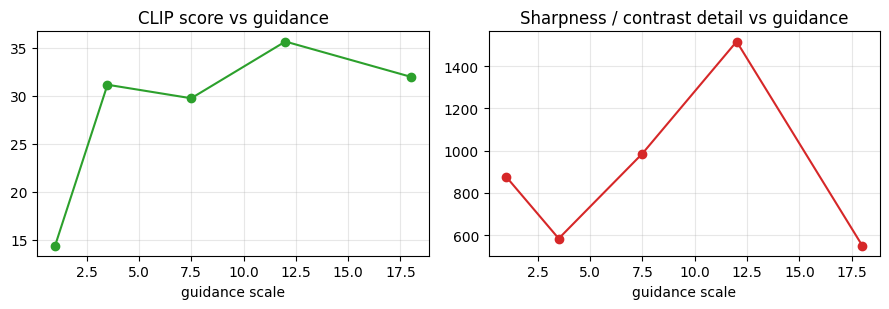

In [9]:
GS_LIST = [1.0, 5.0, 9.0, 15.0] if QUICK_MODE else [1.0, 3.5, 7.5, 12.0, 18.0]
imgs, titles, rows = [], [], []
for g in GS_LIST:
    im, dt = generate(BASE_PROMPT, steps=15, guidance=g, scheduler="DPM++ 2M", experiment="guidance")
    imgs.append(im); titles.append(f"guidance {g}")
    rows.append(dict(guidance=g, time_s=round(dt, 1), sharpness=round(sharpness(im), 1),
                     CLIP=round(clip_score(im, BASE_PROMPT), 2)))
show_grid(imgs, titles, suptitle="Effect of guidance scale (15 steps, DPM++ 2M)")
gs_df = pd.DataFrame(rows); display(gs_df)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(gs_df.guidance, gs_df.CLIP, "o-", c="C2"); ax[0].set_title("CLIP score vs guidance")
ax[1].plot(gs_df.guidance, gs_df.sharpness, "o-", c="C3"); ax[1].set_title("Sharpness / contrast detail vs guidance")
for a in ax: a.set_xlabel("guidance scale"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**What to look for (typical behaviour):**
- `guidance ~ 1` -> the prompt is almost ignored; images are vague, low-contrast and may not show a cabin/lake at all.
- `guidance ~ 5-9` -> best balance: prompt-faithful and natural-looking (7.5 is the widely used default).
- `guidance >= 15` -> over-saturated colours, harsh contrast, "burnt"/artefact-filled textures and reduced diversity, even though prompt adherence may still look strong. The sharpness metric rises partly because of these artefacts, so it must be read together with the images.

## 6. Experiment 3 - Sampling method (scheduler)
Steps = 15, guidance = 7.5, same seed and same starting noise. Different schedulers are different numerical solvers for the same reverse-diffusion process: some converge quickly (DPM++, UniPC), some need more steps (DDIM, PNDM), and ancestral samplers inject fresh noise at every step (so results change with step count and look less stable).

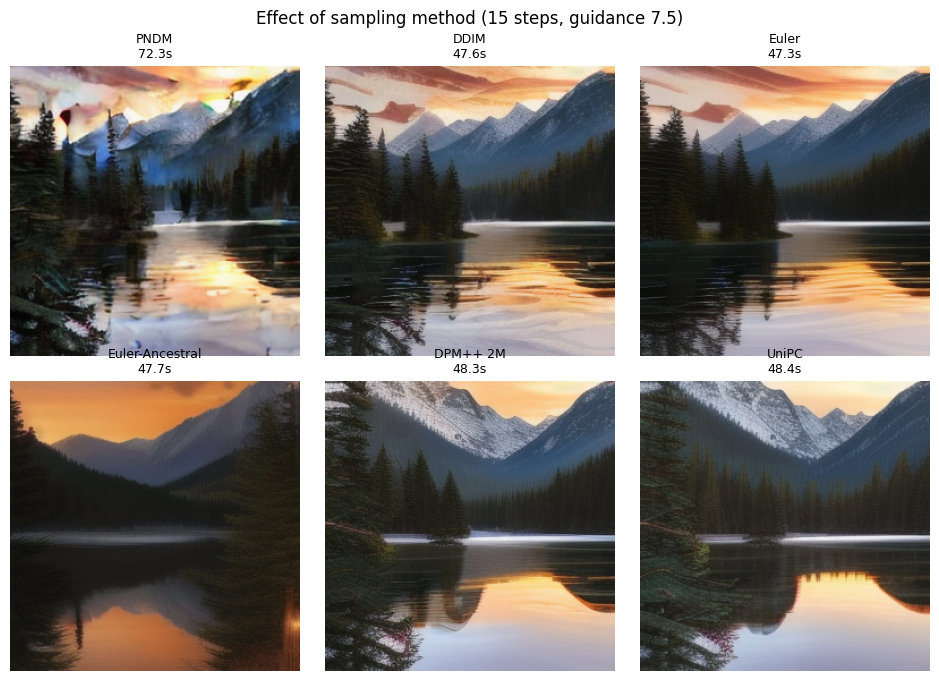

,scheduler,time_s,sharpness,CLIP
0,PNDM,72.3,570.4,29.98
1,DDIM,47.6,880.3,30.02
2,Euler,47.3,764.4,30.02
3,Euler-Ancestral,47.7,149.1,33.27
4,DPM++ 2M,48.3,986.3,29.75
5,UniPC,48.4,620.3,29.09


In [10]:
SCHED_LIST = ["DDIM", "Euler", "DPM++ 2M", "UniPC"] if QUICK_MODE else list(SCHEDULERS.keys())
imgs, titles, rows = [], [], []
for name in SCHED_LIST:
    im, dt = generate(BASE_PROMPT, steps=15, guidance=7.5, scheduler=name, experiment="scheduler")
    imgs.append(im); titles.append(f"{name}\n{dt:.1f}s")
    rows.append(dict(scheduler=name, time_s=round(dt, 1), sharpness=round(sharpness(im), 1),
                     CLIP=round(clip_score(im, BASE_PROMPT), 2)))
show_grid(imgs, titles, ncols=3, suptitle="Effect of sampling method (15 steps, guidance 7.5)")
sch_df = pd.DataFrame(rows); display(sch_df)

### Do schedulers behave differently at *low* step counts?
A short follow-up with only **8 steps** for the fast solvers and DDIM/PNDM, to show which sampler converges best when the budget is tiny.

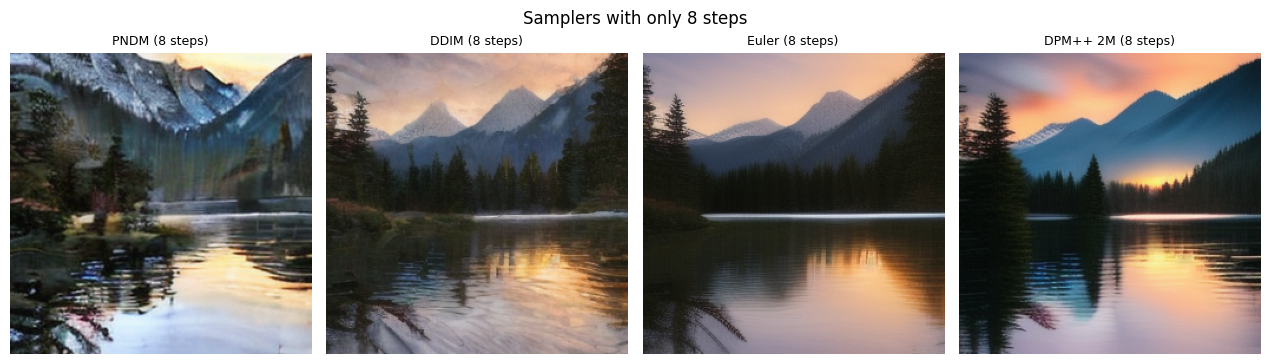

In [11]:
LOW_STEPS = 8
low_list = ["PNDM", "DDIM", "Euler", "DPM++ 2M"] if not QUICK_MODE else ["DDIM", "DPM++ 2M"]
imgs, titles = [], []
for name in low_list:
    im, dt = generate(BASE_PROMPT, steps=LOW_STEPS, guidance=7.5, scheduler=name, experiment="scheduler_low")
    imgs.append(im); titles.append(f"{name} ({LOW_STEPS} steps)")
show_grid(imgs, titles, suptitle="Samplers with only 8 steps")

**What to look for (typical behaviour):**
- **DPM++ 2M / UniPC**: high-order solvers - clean results already at 8-15 steps. Recommended defaults.
- **Euler**: simple and reliable, slightly softer at very low steps.
- **Euler-Ancestral**: adds random noise each step -> more "creative" but less reproducible; it does not converge to one image as steps increase.
- **DDIM / PNDM**: deterministic but need more steps; at 8 steps they may look noisier or blurrier.
- All schedulers cost roughly the **same time per step** (one UNet pass per step, doubled by CFG), so quality-at-equal-steps is what matters.

## 7. Prompt gallery - four themes, best settings
Using the settings found above (DPM++ 2M, 20 steps, guidance 7.5), generate one image per theme. This also answers the questions from the sample notebook: *does the image match the prompt, what happens when the prompt changes, are objects realistic, are there unwanted details?*

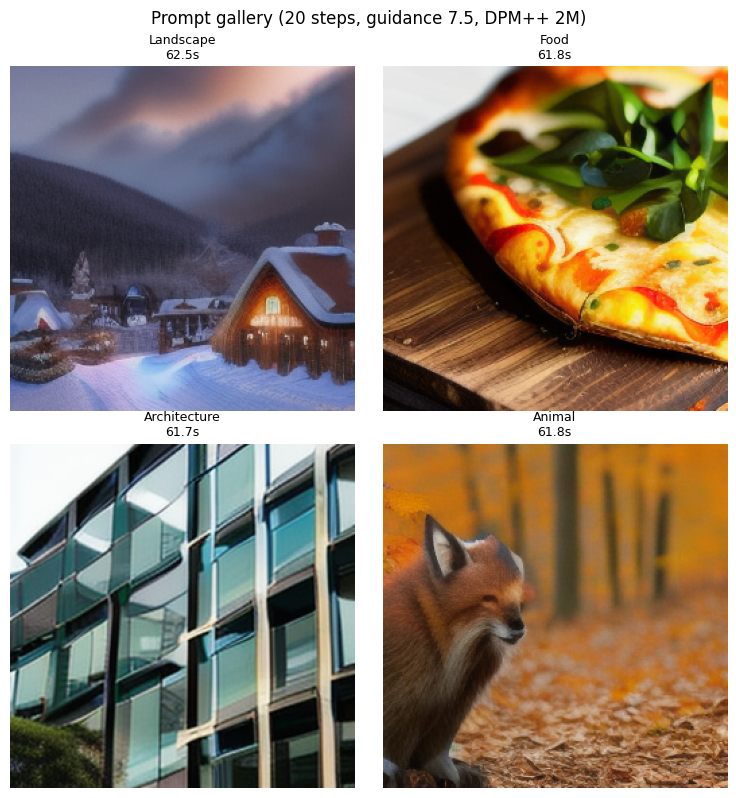

,theme,time_s,CLIP
0,Landscape,62.5,34.23
1,Food,61.8,31.26
2,Architecture,61.7,26.99
3,Animal,61.8,33.37


In [12]:
PROMPT_DATASET = pd.DataFrame({
    "theme": ["Landscape", "Food", "Architecture", "Animal"],
    "prompt": [
        "A snowy mountain village at dusk, warm lights in the windows, smoke from chimneys, photorealistic",
        "A freshly baked pizza with melted cheese and basil on a rustic wooden table, studio lighting, close-up",
        "A modern glass library building with a green rooftop garden, clear sky, architectural photography",
        "A red fox sitting in a golden autumn forest, shallow depth of field, wildlife photography",
    ],
})
if QUICK_MODE: PROMPT_DATASET = PROMPT_DATASET.iloc[:2]

imgs, titles, rows = [], [], []
for _, r in PROMPT_DATASET.iterrows():
    im, dt = generate(r.prompt, steps=20, guidance=7.5, scheduler="DPM++ 2M", experiment="gallery")
    imgs.append(im); titles.append(f"{r.theme}\n{dt:.1f}s")
    rows.append(dict(theme=r.theme, time_s=round(dt, 1), CLIP=round(clip_score(im, r.prompt), 2)))
show_grid(imgs, titles, ncols=2, size=3.8, suptitle="Prompt gallery (20 steps, guidance 7.5, DPM++ 2M)")
display(pd.DataFrame(rows))

## 8. Summary of all runs

,images,avg_time_s,total_time_s
experiment,,,
first_image,1,79.7,79.7
gallery,4,61.9,247.8
guidance,5,45.1,225.6
scheduler,6,51.9,311.6
scheduler_low,4,35.0,140.0
steps,4,52.4,209.6


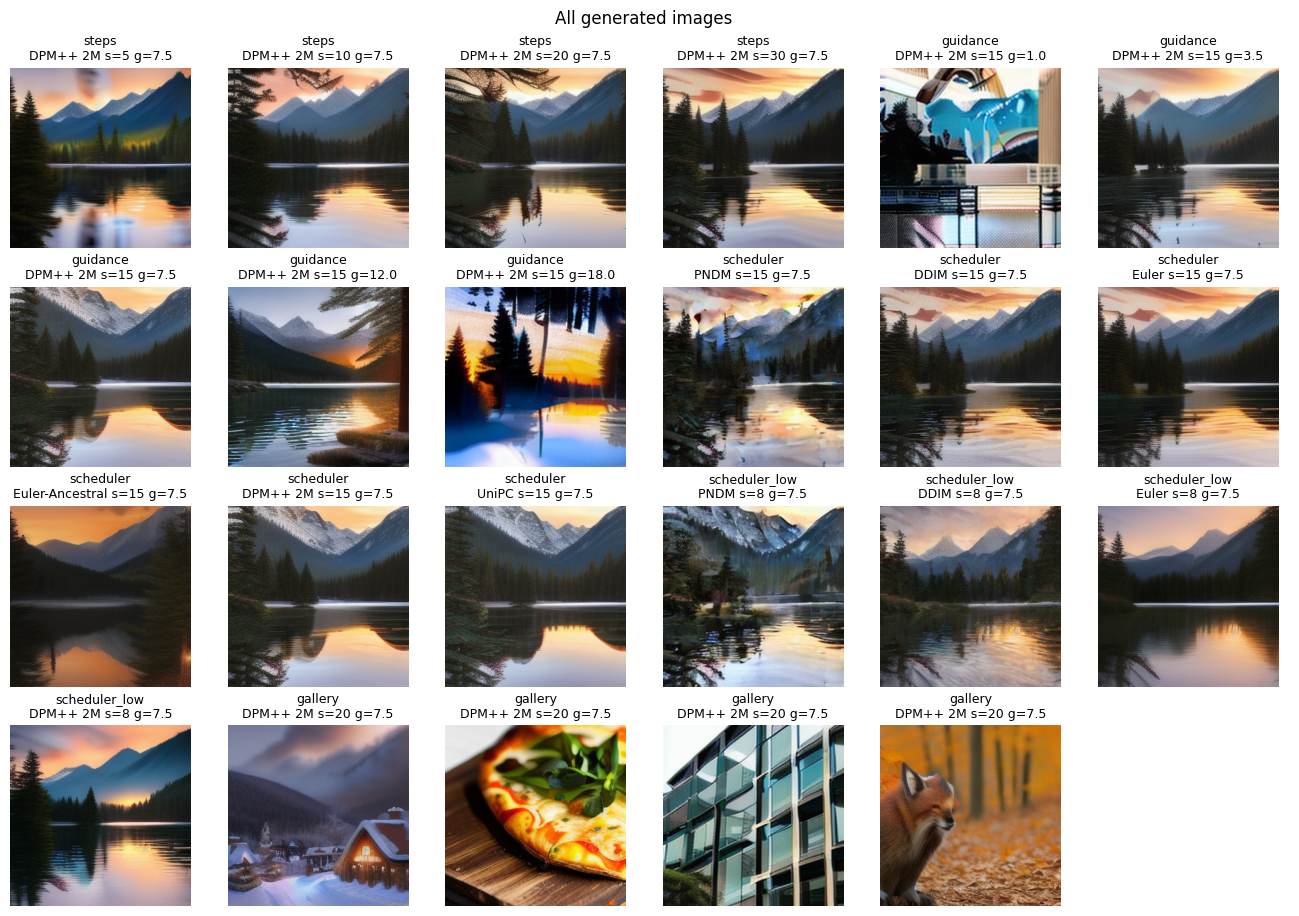

In [13]:
log = pd.DataFrame([{k: v for k, v in r.items() if k != "image"} for r in records])
display(log.groupby("experiment").agg(images=("time_s", "count"), avg_time_s=("time_s", "mean"),
                                      total_time_s=("time_s", "sum")).round(1))

# Save a contact sheet of every image generated
sel = [r for r in records if r["experiment"] != "first_image"]
show_grid([r["image"] for r in sel],
          [f"{r['experiment']}\n{r['scheduler']} s={r['steps']} g={r['guidance']}" for r in sel],
          ncols=6, size=2.2, suptitle="All generated images")

## 9. Conclusions

| Parameter | Too low | Sweet spot (CPU, tiny-sd) | Too high |
|---|---|---|---|
| **Inference steps** | blurry, unfinished, weak structure | ~15-25 steps | little visible gain, run time grows linearly |
| **Guidance scale** | ignores prompt, vague, low contrast | ~5-9 (default 7.5) | over-saturated, harsh, artefacts, less diversity |
| **Sampler** | - | DPM++ 2M or UniPC (good at 8-20 steps) | Euler-A is non-convergent (random); DDIM/PNDM need more steps |

**Key takeaways**
1. Steps and sampler interact: a better sampler (DPM++ / UniPC) reaches good quality with ~half the steps of DDIM/PNDM, which is what makes diffusion usable on a CPU.
2. Guidance trades **prompt fidelity** against **image naturalness/diversity** - more is not always better.
3. The seed fixes the initial noise (layout); prompt, steps, guidance and sampler then decide content and quality.
4. Limitations: small model + low resolution -> anatomy/text errors; metrics such as CLIP score and Laplacian sharpness are only rough proxies and must be combined with visual inspection.
